# D26: Training Effectiveness Data Analysis
## Notebook 02: Exploratory Data Analysis & KPI Synthesis
**Academic Institution:** ABES Engineering College | MCA 2nd Year  
**Prepared For:** Program Manager, EdTech, HCLTech | HR Leadership  
**Domain:** Human Resources Analytics  
**Sprint Focus:** Sprint 2 (`v0.2.0`) - Exploratory Data Analysis, Trend Discovery & Behavioral Analysis  

---
### Notebook Objectives:
1. Examine distributions of training participation, ratings, and attendance across the organization.
2. Uncover the 3 primary built-in trends and 2 key correlations.
3. Quantify the relationship between training investment and rating improvements across departments.
4. Investigate the anomalous "Trained Talent Flight" segment.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
pd.set_option('display.max_columns', None)

clean_path = os.path.join("..", "data", "clean", "training_effectiveness_cleaned.csv")
if not os.path.exists(clean_path):
    clean_path = os.path.join("data", "clean", "training_effectiveness_cleaned.csv")

df = pd.read_csv(clean_path)
print(f"Cleaned dataset loaded: {df.shape[0]} records, {df.shape[1]} features.")
df.head(3)


Cleaned dataset loaded: 5000 records, 28 features.


,employee_id,employee_name,department,job_role,gender,city,state,join_date,exit_date,experience_years,salary,pre_training_rating,training_program_name,training_type,training_hours,training_score,performance_rating,attendance_days,late_arrivals,manager_id,hr_cost,attrition_flag,rating_improvement,rating_uplift_pct,training_tier,performance_category,cost_per_training_hour,is_flight_risk
0,EMP-1001,Daksh Bakshi,Customer Success,Technical Support Lead,Male,Noida,Uttar Pradesh,2024-01-21,2024-06-17,3.5,922000,3.2,Advanced Data Analytics & Power BI,Technical,46.1,73.3,3.9,220,3,MGR-1108,47066,Yes,0.7,21.9,High (>35h),Exceeds Expectations,1020.95,False
1,EMP-1002,Laksh Konda,Engineering,QA Engineer,Male,Pune,Maharashtra,2024-07-08,NaN,4.6,1296000,3.0,Full-Stack Cloud & DevOps,Technical,7.4,40.6,2.6,226,12,MGR-1044,10893,No,-0.4,-13.3,Minimal (<15h),Meets Expectations,1472.03,False
2,EMP-1003,Isaac Dewan,Operations,Operations Manager,Male,Bengaluru,Karnataka,2025-01-22,NaN,4.5,933000,3.2,Enterprise Consultative Selling,Domain,9.5,46.4,2.9,204,10,MGR-1060,11161,No,-0.3,-9.4,Minimal (<15h),Meets Expectations,1174.84,False


### 1. Executive Summary KPIs

In [2]:
total_employees = len(df)
active_trainees = (df['training_hours'] >= 15).sum()
participation_rate = (active_trainees / total_employees) * 100
avg_training_hours = df['training_hours'].mean()
mean_rating_uplift = df['rating_improvement'].mean()
overall_attrition_rate = (df['attrition_flag'] == 'Yes').mean() * 100
total_hr_cost = df['hr_cost'].sum()

print("=" * 60)
print("             EXECUTIVE WORKFORCE TRAINING KPIS")
print("=" * 60)
print(f"Total Workforce Analyzed         : {total_employees:,}")
print(f"Training Participation Rate (>15h): {participation_rate:.1f}%")
print(f"Average Training Hours / Emp     : {avg_training_hours:.1f} Hours")
print(f"Average Performance Uplift       : +{mean_rating_uplift:.2f} Rating Points")
print(f"Workforce Attrition Rate         : {overall_attrition_rate:.1f}%")
print(f"Total HR / L&D Investment        : INR {total_hr_cost/1e7:.2f} Crores")
print("=" * 60)


             EXECUTIVE WORKFORCE TRAINING KPIS
Total Workforce Analyzed         : 5,000
Training Participation Rate (>15h): 75.1%
Average Training Hours / Emp     : 27.4 Hours
Average Performance Uplift       : +0.53 Rating Points
Workforce Attrition Rate         : 12.9%
Total HR / L&D Investment        : INR 14.93 Crores


### 2. Univariate Analysis: Training Hours, Ratings & Costs

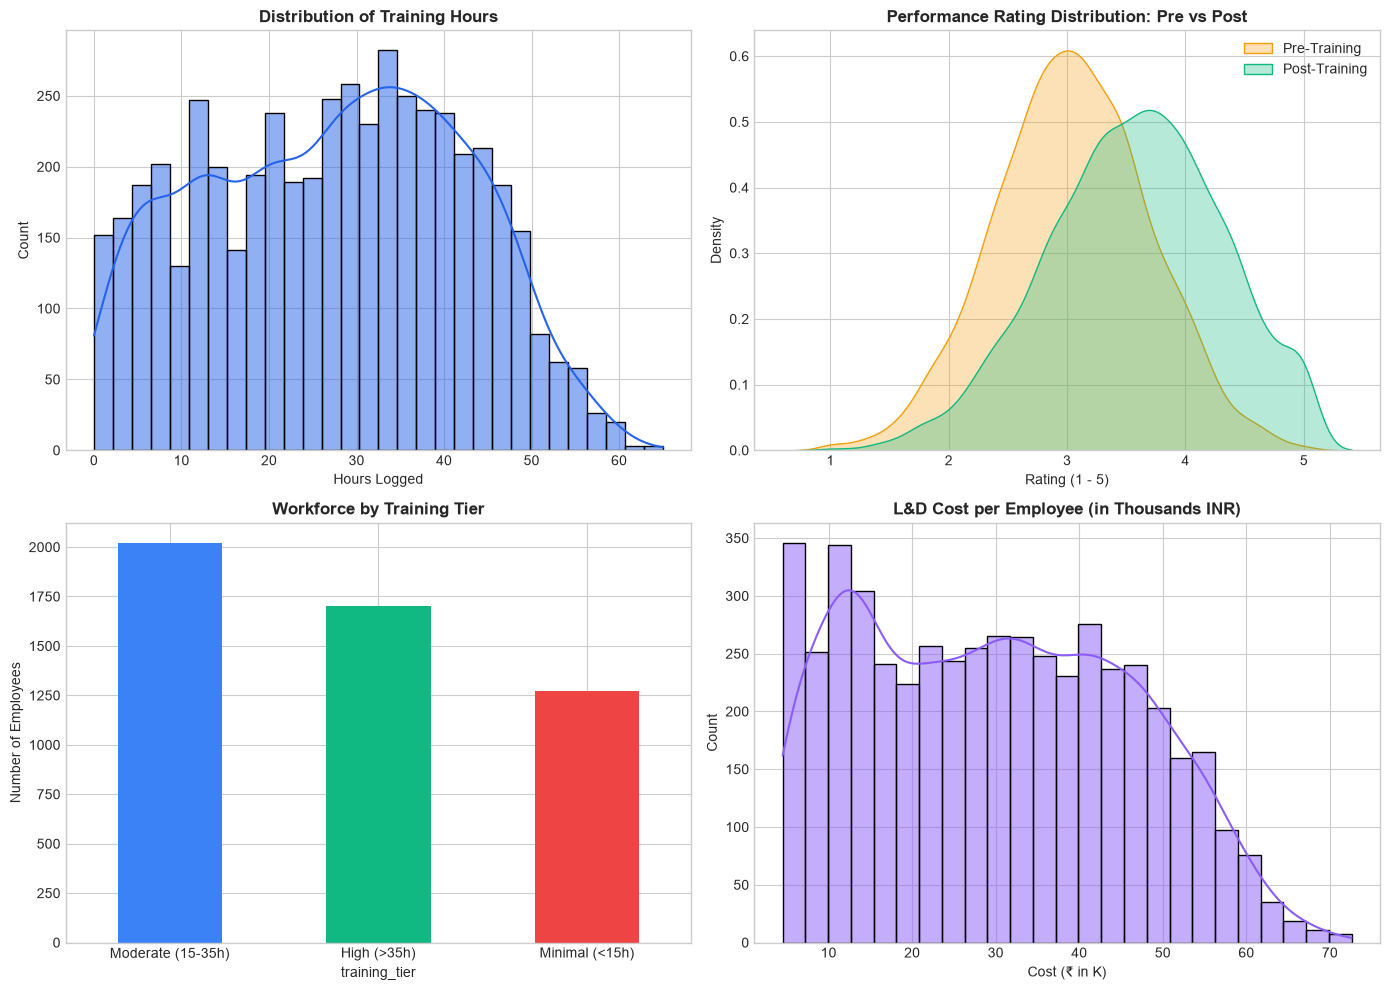

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution of Training Hours
sns.histplot(df['training_hours'], bins=30, kde=True, ax=axes[0, 0], color='#2563eb')
axes[0, 0].set_title('Distribution of Training Hours', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Hours Logged')

# 2. Performance Rating Pre vs Post
sns.kdeplot(df['pre_training_rating'], ax=axes[0, 1], label='Pre-Training', color='#f59e0b', fill=True, alpha=0.3)
sns.kdeplot(df['performance_rating'], ax=axes[0, 1], label='Post-Training', color='#10b981', fill=True, alpha=0.3)
axes[0, 1].set_title('Performance Rating Distribution: Pre vs Post', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Rating (1 - 5)')
axes[0, 1].legend()

# 3. Training Tier Breakdown
df['training_tier'].value_counts().plot(kind='bar', ax=axes[1, 0], color=['#3b82f6', '#10b981', '#ef4444'])
axes[1, 0].set_title('Workforce by Training Tier', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Number of Employees')
axes[1, 0].tick_params(axis='x', rotation=0)

# 4. HR Training Cost Distribution
sns.histplot(df['hr_cost'] / 1000, bins=25, kde=True, ax=axes[1, 1], color='#8b5cf6')
axes[1, 1].set_title('L&D Cost per Employee (in Thousands INR)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Cost (₹ in K)')

plt.tight_layout()
plt.show()


### 3. Bivariate Analysis: Training Impact on Performance by Department

In [4]:
dept_analysis = df.groupby('department').agg(
    Employee_Count=('employee_id', 'count'),
    Avg_Training_Hours=('training_hours', 'mean'),
    Avg_Training_Score=('training_score', 'mean'),
    Mean_Pre_Rating=('pre_training_rating', 'mean'),
    Mean_Post_Rating=('performance_rating', 'mean'),
    Mean_Rating_Improvement=('rating_improvement', 'mean'),
    Attrition_Rate=('attrition_flag', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

dept_analysis = dept_analysis.sort_values(by='Mean_Rating_Improvement', ascending=False)
dept_analysis.round(2)


,department,Employee_Count,Avg_Training_Hours,Avg_Training_Score,Mean_Pre_Rating,Mean_Post_Rating,Mean_Rating_Improvement,Attrition_Rate
4,Human Resources,495,27.75,72.94,3.05,3.61,0.56,12.12
3,Finance,515,27.59,73.20,3.04,3.59,0.54,14.95
1,Data Science & AI,790,27.28,71.34,3.03,3.58,0.54,10.89
5,Operations,500,28.75,72.35,3.06,3.59,0.54,16.00
0,Customer Success,420,27.20,72.06,3.02,3.55,0.53,14.05
2,Engineering,1389,26.86,71.91,3.06,3.58,0.53,11.30
6,Sales & Marketing,891,27.19,70.78,3.00,3.51,0.52,14.03


C:\Users\rahul\AppData\Local\Temp\ipykernel_8364\2374274637.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_analysis, x='Mean_Rating_Improvement', y='department', palette='Blues_r')


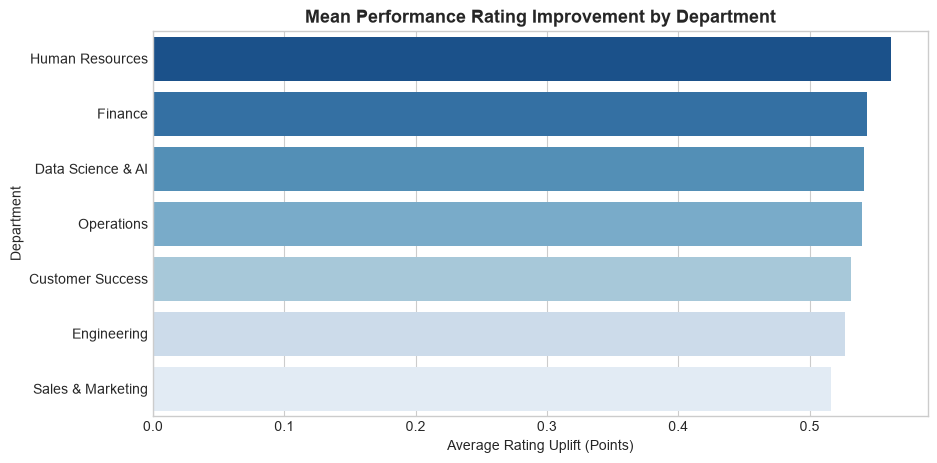

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(data=dept_analysis, x='Mean_Rating_Improvement', y='department', palette='Blues_r')
plt.title('Mean Performance Rating Improvement by Department', fontsize=13, fontweight='bold')
plt.xlabel('Average Rating Uplift (Points)')
plt.ylabel('Department')
plt.show()


### 4. Correlation Analysis: Proving Built-in Trends & Relationships

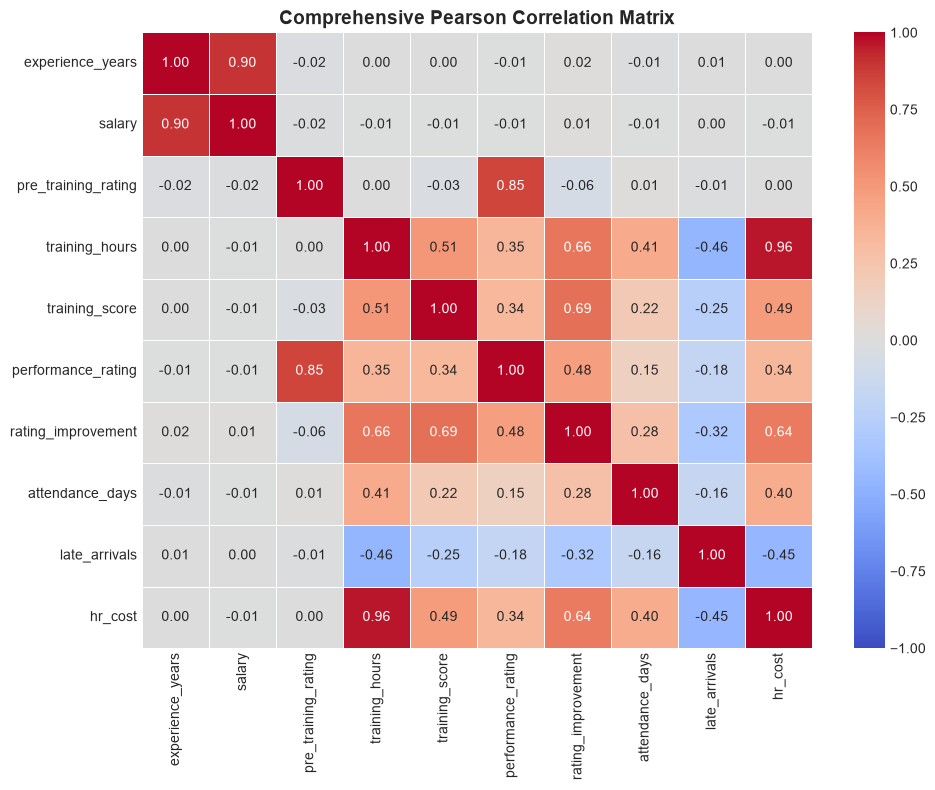

In [6]:
numeric_cols = [
    'experience_years', 'salary', 'pre_training_rating', 
    'training_hours', 'training_score', 'performance_rating', 
    'rating_improvement', 'attendance_days', 'late_arrivals', 'hr_cost'
]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Comprehensive Pearson Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 5. Attrition Analysis & The "Trained Talent Flight" Anomaly

In [7]:
# Compare Attrition across Training Tiers
tier_attrition = df.groupby('training_tier')['attrition_flag'].apply(lambda x: (x == 'Yes').mean() * 100)
print("Attrition Rate by Training Tier:")
print(tier_attrition.round(2))

# Examine the Special Segment: High Trained + High Rating + Undercompensated
flight_risk_group = df.groupby('is_flight_risk')['attrition_flag'].apply(lambda x: (x == 'Yes').mean() * 100)
print('\nAttrition Rate Comparison for Poaching Risk Anomaly:')
print(flight_risk_group.round(2))


Attrition Rate by Training Tier:
training_tier
High (>35h)          11.62
Minimal (<15h)       18.37
Moderate (15-35h)    10.48
Name: attrition_flag, dtype: float64

Attrition Rate Comparison for Poaching Risk Anomaly:
is_flight_risk
False    11.08
True     50.88
Name: attrition_flag, dtype: float64


C:\Users\rahul\AppData\Local\Temp\ipykernel_8364\3305971078.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=flight_risk_df, x='Cohort', y='Attrition Rate (%)', palette=['#94a3b8', '#10b981', '#ef4444'])


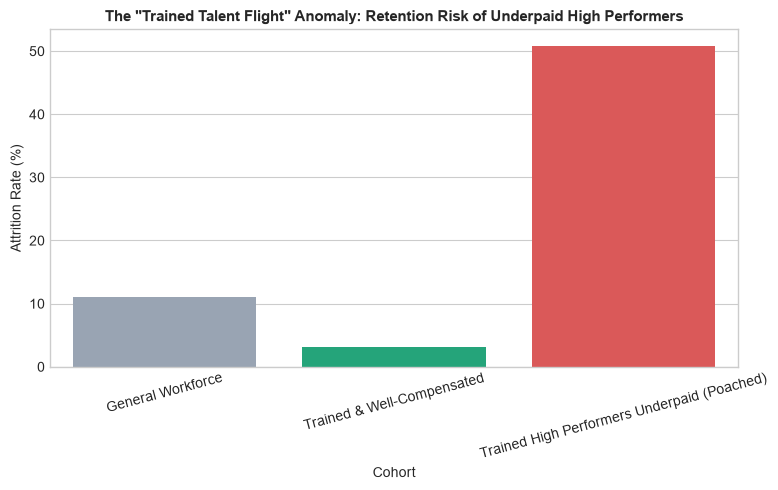

In [8]:
plt.figure(figsize=(8, 5))
flight_risk_df = pd.DataFrame({
    'Cohort': ['General Workforce', 'Trained & Well-Compensated', 'Trained High Performers Underpaid (Poached)'],
    'Attrition Rate (%)': [
        (df[~df['is_flight_risk']]['attrition_flag'] == 'Yes').mean() * 100,
        (df[(df['training_hours'] >= 40) & (df['performance_rating'] >= 4.0) & (~df['is_flight_risk'])]['attrition_flag'] == 'Yes').mean() * 100,
        (df[df['is_flight_risk']]['attrition_flag'] == 'Yes').mean() * 100
    ]
})

sns.barplot(data=flight_risk_df, x='Cohort', y='Attrition Rate (%)', palette=['#94a3b8', '#10b981', '#ef4444'])
plt.title('The "Trained Talent Flight" Anomaly: Retention Risk of Underpaid High Performers', fontsize=11, fontweight='bold')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
